<a href="https://colab.research.google.com/github/Samuel2253360/Proyecto-Estructuras/blob/main/proyecto_grafos_email_eu_core.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aplicación de la teoría de grafos
## Dataset: *email-Eu-core*

**Asignatura:** Estructuras de Datos — UIS, 2026-I  
**Integrantes:**
| # | Nombre | Tarea asignada |
|---|--------|----------------|
| 1 | *(Nombre integrante 1)* | Tarea 1 — Resiliencia y nodo más influyente |
| 2 | *(Nombre integrante 2)* | Tarea 2 — Comunicación inter-departamental |
| 3 | *Angel Camilo Pachon Padilla* | Tarea 3 — Componentes conexas y accesibilidad |
| 4 | *(Samuel Alejandro Fuentes Sandoval)* | Tarea 4 — Detección de comunidades |

---
> **Nota:** El algoritmo de Dijkstra **no está permitido** en ninguna tarea.

---
# 1. Descripción del dataset

## Origen y contexto

La red **email-Eu-core** fue generada a partir de datos de correo electrónico de una gran institución de investigación europea. Contiene información anonimizada sobre toda la comunicación por correo entre los miembros de la institución.

Existe una arista dirigida `(u → v)` si la persona `u` envió **al menos un correo** a la persona `v`. La red representa únicamente la comunicación interna (el "núcleo"), sin mensajes externos.

El dataset incluye también las **pertenencias reales a departamentos** (*ground-truth community memberships*): cada nodo pertenece exactamente a uno de los **42 departamentos** del instituto.

## Archivos

| Archivo | Descripción |
|---------|-------------|
| `email-Eu-core.txt` | Aristas del grafo: cada línea `u v` indica que `u` envió correo a `v` |
| `email-Eu-core-department-labels.txt` | Etiquetas: cada línea `nodo departamento` |

## Estadísticas del dataset

| Estadística | Valor |
|-------------|-------|
| Nodos | 1 005 |
| Aristas | 25 571 |
| Nodos en la WCC más grande | 986 (98.1 %) |
| Aristas en la WCC más grande | 25 552 (99.9 %) |
| Nodos en la SCC más grande | 803 (79.9 %) |
| Aristas en la SCC más grande | 24 729 (96.7 %) |
| Coeficiente de agrupamiento promedio | 0.3994 |
| Número de triángulos | 105 461 |
| Fracción de triángulos cerrados | 0.1085 |
| Diámetro (camino más corto más largo) | 7 |
| Diámetro efectivo (percentil 90) | 2.9 |

## Fuentes

- Yin et al. "Local Higher-order Graph Clustering." KDD 2017.
- Leskovec, Kleinberg y Faloutsos. "Graph Evolution: Densification and Shrinking Diameters." ACM TKDD, 2007.
- https://snap.stanford.edu/data/email-Eu-core.html

---
# 2. Carga y exploración inicial del grafo

In [2]:
# Instalación de dependencias (solo si se ejecuta en Colab)
# !pip install networkx matplotlib

In [3]:
from collections import defaultdict, deque
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Paleta de colores para visualizaciones
COLORES_DEPT = plt.cm.tab20

In [4]:
# ── Rutas y descarga de datos ─────────────────────────────────────────────────
# Si los archivos no están en el entorno (por ejemplo, en una sesión nueva de
# Colab), se descargan desde SNAP. Si ya los subiste o están en Drive, se usan.
import gzip
import shutil
import urllib.request
from pathlib import Path

RUTA_ARISTAS = Path('email-Eu-core.txt')
RUTA_ETIQUETAS = Path('email-Eu-core-department-labels.txt')

def descargar_si_no_existe(ruta, url):
    if ruta.exists():
        return
    print(f'Descargando {ruta.name} desde SNAP...')
    with urllib.request.urlopen(url, timeout=60) as respuesta:
        with gzip.GzipFile(fileobj=respuesta) as archivo_comprimido:
            with ruta.open('wb') as archivo:
                shutil.copyfileobj(archivo_comprimido, archivo)

descargar_si_no_existe(
    RUTA_ARISTAS,
    'https://snap.stanford.edu/data/email-Eu-core.txt.gz',
)
descargar_si_no_existe(
    RUTA_ETIQUETAS,
    'https://snap.stanford.edu/data/email-Eu-core-department-labels.txt.gz',
)

# ── Lectura del grafo ──────────────────────────────────────────────────────────
# Representación: lista de adyacencia (diccionario de conjuntos)
# grafo[u] = conjunto de nodos a los que u envió correo
grafo = defaultdict(set)       # grafo dirigido
grafo_inv = defaultdict(set)   # grafo transpuesto (útil para SCC y centralidad)
nodos = set()

with open(RUTA_ARISTAS) as f:
    for linea in f:
        linea = linea.strip()
        if not linea or linea.startswith('#'):
            continue
        u, v = map(int, linea.split())
        if u == v:             # ignorar auto-bucles
            continue
        grafo[u].add(v)
        grafo_inv[v].add(u)
        nodos.update([u, v])

# Garantizar que todos los nodos estén en ambos diccionarios
for n in list(nodos):
    grafo[n]     # crea entrada vacía si no existe
    grafo_inv[n]

num_nodos  = len(nodos)
num_aristas = sum(len(v) for v in grafo.values())

print(f'Nodos:   {num_nodos}')
print(f'Aristas: {num_aristas}')

Descargando email-Eu-core.txt desde SNAP...
Descargando email-Eu-core-department-labels.txt desde SNAP...
Nodos:   986
Aristas: 24929


In [5]:
# Mostrar las primeras 10 líneas del archivo de etiquetas para verificar su formato exacto
with open(RUTA_ETIQUETAS, 'r') as f:
    for _ in range(10):
        line = f.readline()
        if not line:
            break
        print(repr(line))

'0 1\n'
'1 1\n'
'2 21\n'
'3 21\n'
'4 21\n'
'5 25\n'
'6 25\n'
'7 14\n'
'8 14\n'
'9 14\n'


In [6]:
# ── Lectura de etiquetas de departamento ──────────────────────────────────────
# departamento[nodo] = id_departamento  (0 a 41)
departamento = {}

with open(RUTA_ETIQUETAS) as f:
    for linea in f:
        linea = linea.strip()
        if not linea:
            continue
        nodo, dept = map(int, linea.split())
        departamento[nodo] = dept

num_departamentos = len(set(departamento.values()))
print(f'Departamentos distintos: {num_departamentos}')

# Nodos del grafo sin etiqueta (si los hubiera)
sin_etiqueta = nodos - set(departamento.keys())
print(f'Nodos sin etiqueta de departamento: {len(sin_etiqueta)}')

Departamentos distintos: 42
Nodos sin etiqueta de departamento: 0


=== Estadísticas de grado ===
Grado de salida  — máx:  333  prom: 25.28
Grado de entrada — máx:  211  prom: 25.28


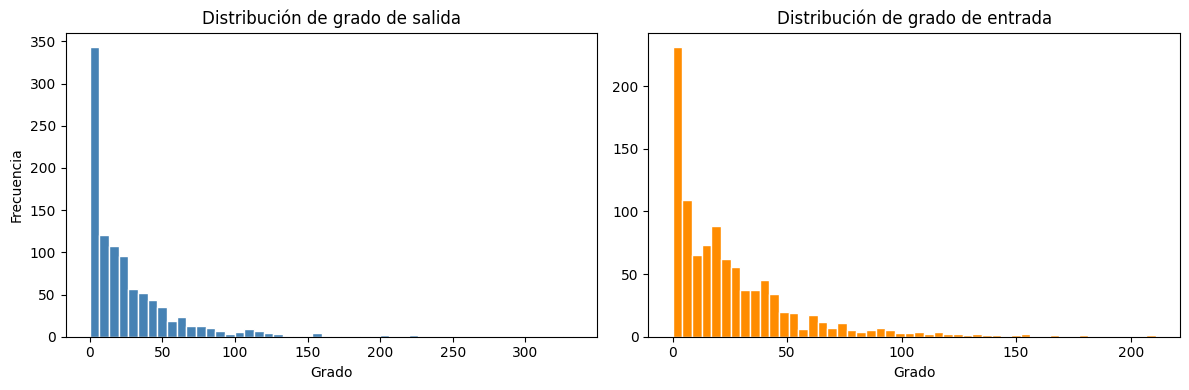

In [7]:
# ── Exploración básica ────────────────────────────────────────────────────────
grado_salida  = {n: len(grafo[n])     for n in nodos}
grado_entrada = {n: len(grafo_inv[n]) for n in nodos}
grado_total   = {n: grado_salida[n] + grado_entrada[n] for n in nodos}

print('=== Estadísticas de grado ===')
print(f'Grado de salida  — máx: {max(grado_salida.values()):>4}  '
      f'prom: {sum(grado_salida.values()) / num_nodos:.2f}')
print(f'Grado de entrada — máx: {max(grado_entrada.values()):>4}  '
      f'prom: {sum(grado_entrada.values()) / num_nodos:.2f}')

# Distribución del grado total
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(list(grado_salida.values()),  bins=50, color='steelblue',  edgecolor='white')
axes[0].set_title('Distribución de grado de salida');  axes[0].set_xlabel('Grado'); axes[0].set_ylabel('Frecuencia')
axes[1].hist(list(grado_entrada.values()), bins=50, color='darkorange', edgecolor='white')
axes[1].set_title('Distribución de grado de entrada'); axes[1].set_xlabel('Grado')
plt.tight_layout()
plt.show()

---
# Tarea 1 — Resiliencia de la red: el contacto más influyente
**Integrante:** Santiago Jimenez Rico

## 1.1 Descripción del problema


En una organicación la comunicación no es uniforme: hay personas que envian y reciben mas correos que el resto, y otras que funcionan como puentes entre grupos que no se comunican mucho.

Entones nos surgen dos preguntas:
1. cual es la persona mas influyente de la red y a que departamento pertenece?
2. que tan resiliente es la red? es decir, que tanto se deteriora la comunicación cuando dicha persona deja de estar disponible, y cuantas personas habrai que sacar para fragmentar la red?

El termino influyente se puede interpretar de varias maneras asi que se tomarán 3: la actividad, la intermediación y la influencia indirecta:
- **actividad:** a cuantas personas contacta o por cuantas es contactada
- **Intermediación:** en cuantas comunicaciónes funge como puente
- **Influencia indirecta:** que tan importante es quien la contacta

se busca a la persona que ocupe la posición mas alta en las tres medidas y se analiza si hay coincidencia.

Y para saber que tan reciliente es la red se eliminarán personas de la red: en orden de importancia y de manera aleatoria, y se medirá el efecto sobre la capacidad de comunicación: tamaño de la componente fuertemente conexa más grande, número de pares de personas que dejan de poder comunicarse y variación de la distancia promedio entre ellas.

## 1.2 Equivalencia matemática

## 1.2 Equivalencia matemática

### Modelo

La red de correos se modela como un grafo dirigido y sin pesos $G = (V, E)$, donde:

- $V$ es el conjunto de personas, con $n = |V| = 1\,005$.
- $E \subseteq V \times V$ es el conjunto de aristas: $(u, v) \in E$ si y solo si la persona $u$ envió al menos un correo a la persona $v$. Se tiene $m = |E| = 25\,571$ y se excluyen los auto-bucles.

Un **camino** de $u$ a $v$ es una sucesión de aristas que lleva de $u$ a $v$ respetando su dirección. La **distancia** $\operatorname{dist}(u,v)$ es el menor número de aristas de un camino de $u$ a $v$. Como el grafo no tiene pesos, esta distancia puede calcularse con una búsqueda en anchura (BFS), sin necesidad de algoritmos para grafos ponderados como Dijkstra.

### Correspondencia entre el problema real y el problema matemático

| Concepto del problema | Objeto matemático |
|---|---|
| Persona que envía o recibe muchos correos (*actividad*) | Grado de salida y de entrada de un vértice |
| Persona que actúa como puente (*intermediación*) | Centralidad de intermediación (*betweenness*) |
| Importancia de quien contacta a la persona (*influencia indirecta*) | PageRank |
| La persona deja de estar disponible | Eliminación de un vértice: grafo $G - v$ |
| La comunicación se deteriora | Cambio en las componentes fuertemente conexas, en los pares alcanzables y en las distancias |

### Actividad: centralidad de grado

El **grado de salida** $d^+(v) = |\{w \in V : (v,w) \in E\}|$ cuenta a cuántas personas escribió $v$, y el **grado de entrada** $d^-(v) = |\{u \in V : (u,v) \in E\}|$ cuenta cuántas personas le escribieron. Ambos se dividen entre $n-1$ para obtener valores comparables entre redes.

### Intermediación: centralidad de intermediación

Sea $\sigma_{st}$ el número de caminos más cortos de $s$ a $t$, y $\sigma_{st}(v)$ cuántos de ellos pasan por $v$. La centralidad de intermediación de $v$ es:

$$
C_B(v) = \sum_{\substack{s,t \in V \\ s \neq v \neq t,\ \sigma_{st} > 0}} \frac{\sigma_{st}(v)}{\sigma_{st}}
$$

Un valor alto indica que muchas comunicaciones de mínima longitud entre otras personas dependen de $v$. Para el grafo dirigido, se normaliza dividiendo entre $(n-1)(n-2)$.

### Influencia indirecta: PageRank

PageRank asigna a cada persona la probabilidad de encontrarla en el estado estacionario de un recorrido aleatorio sobre el grafo: desde la persona actual se sigue, con probabilidad $\alpha$, un correo hacia alguno de sus contactos elegido al azar y, con probabilidad $1-\alpha$, se salta a una persona cualquiera. Formalmente, $PR$ es la solución de:

$$
PR(v) = \frac{1-\alpha}{n} + \alpha \left( \sum_{u : (u,v) \in E} \frac{PR(u)}{d^+(u)} + \frac{1}{n}\sum_{u : d^+(u)=0} PR(u) \right)
$$

con $\alpha = 0.85$. El último término reparte uniformemente el peso de las personas que no enviaron correos. Una persona tiene PageRank alto no solo si recibe muchos correos, sino si los recibe de personas que a su vez son muy contactadas, lo cual formaliza la idea de "importancia de quien la contacta".

### Combinación de las tres medidas

Cada medida produce un ordenamiento distinto de las personas. Se compararán estos ordenamientos y se identificará a la persona con mejor posición conjunta, es decir, la que aparezca entre las $k$ primeras de las tres medidas o la de menor posición promedio. También se medirá el grado de coincidencia entre los ordenamientos con el coeficiente de correlación de Spearman.

### Resiliencia: eliminación de vértices

Para un conjunto $S \subset V$ de personas que dejan de estar disponibles, la red restante es el subgrafo inducido $G_S = G - S$, con vértices $V \setminus S$ y las aristas de $E$ que unen dos vértices de $V \setminus S$. Se consideran dos estrategias para elegir $S_k$, el conjunto de las $k$ personas eliminadas:

- **Dirigida:** las $k$ personas con mayor importancia según una de las medidas anteriores (ordenamiento calculado sobre $G$).
- **Aleatoria:** $k$ personas elegidas al azar, repitiendo el experimento varias veces y promediando.

En cada paso se miden tres cantidades sobre $G_S$, con $n_S = n - |S|$:

1. **Tamaño de la componente fuertemente conexa más grande,** relativo al original:
$$s(S) = \frac{|C_{\max}(G_S)|}{|C_{\max}(G)|}$$
2. **Fracción de pares que dejan de poder comunicarse.** Sea $R_S(u)$ el conjunto de nodos alcanzables desde $u$ en $G_S$:
$$f(S) = 1 - \frac{|\{(u,v) : u \neq v,\ v \in R_S(u)\}|}{n_S(n_S - 1)}$$
3. **Distancia promedio entre pares alcanzables:**
$$L(S) = \frac{1}{|P_S|} \sum_{(u,v) \in P_S} \operatorname{dist}(u,v), \quad P_S = \{(u,v) : u \neq v,\ v \in R_S(u)\}$$

**Criterio de fragmentación.** Se dice que la red queda fragmentada cuando la componente fuertemente conexa más grande se reduce a la mitad o menos de su tamaño original. El número de personas que hay que retirar es entonces:
$$k^* = \min \{ k : s(S_k) \leq 0.5 \}$$

*(Explicar la equivalencia con el problema matemático: centralidad en grafos — grado, intermediación (betweenness) — y resiliencia de redes. Definir formalmente qué es la centralidad de intermediación sin usar Dijkstra, usando BFS sobre el grafo no ponderado.)*

## 1.3 Alternativas de solución

Contrastar las siguientes opciones y justificar la selección:

| Algoritmo | Descripción | Complejidad | Observación |
|-----------|-------------|-------------|-------------|
| Centralidad de grado | Contar in/out-degree | O(V + E) | Simple, no captura intermediarios |
| Centralidad de intermediación (BFS) | Brandes con BFS | O(V · E) | Identifica puentes de comunicación |
| PageRank (implementación propia) | Flujo de autoridad | O(k · (V + E)) | Captura influencia indirecta |

*(Seleccionar y justificar. Recordar: Dijkstra no permitido.)*

## 1.4 Implementación

In [8]:
# ── Tarea 1: Resiliencia y nodo más influyente ────────────────────────────────
# TODO: implementar el algoritmo seleccionado
# Sugerencia de estructura:
#
#   def centralidad_grado(grafo, grafo_inv):
#       """Retorna dict {nodo: (grado_entrada, grado_salida, total)}"""
#       ...
#
#   def bfs_caminos(grafo, origen):
#       """BFS desde 'origen'; retorna distancias y listas de predecesores."""
#       ...
#
#   def centralidad_intermediacion(grafo, nodos):
#       """Algoritmo de Brandes usando BFS (sin Dijkstra)."""
#       ...
#
#   def impacto_eliminacion(grafo, grafo_inv, nodo_critico):
#       """Simula la eliminación de 'nodo_critico' y mide la fragmentación."""
#       ...

pass

## 1.5 Resultados y análisis

*(Presentar: el top-k de nodos más influyentes, la visualización de centralidades, y el análisis del impacto de eliminar el nodo más importante. ¿Cuánto se fragmenta la red?)*

In [9]:
# ── Visualización de resultados — Tarea 1 ────────────────────────────────────
# TODO

---
# Tarea 2 — Comunicación inter-departamental
**Integrante:** *(Nombre integrante 2)*

## 2.1 Descripción del problema

*(Describir el problema real: ¿cómo se comunican entre sí los 42 departamentos del instituto? ¿Hay departamentos que funcionan como silos aislados? ¿Cuáles son los puentes departamentales?)*

## 2.2 Equivalencia matemática

*(Explicar la construcción de un grafo de departamentos a partir del grafo original: contracción de nodos por comunidad etiquetada. El grafo resultante tendrá a lo sumo 42 nodos; cada arista pesada representa el volumen de correos entre dos departamentos.)*

## 2.3 Alternativas de solución

| Algoritmo | Descripción | Complejidad | Observación |
|-----------|-------------|-------------|-------------|
| Grafo de departamentos (contracción) | Construir meta-grafo | O(E) | Directo con las etiquetas |
| Matriz de flujo inter-dept | Conteo de aristas cruzadas | O(E) | Visualizable como heatmap |
| BFS/DFS sobre el meta-grafo | Accesibilidad entre departamentos | O(42²) | Sobre el grafo condensado |

*(Seleccionar y justificar.)*

## 2.4 Implementación

In [10]:
# ── Tarea 2: Comunicación inter-departamental ─────────────────────────────────
# TODO: implementar el algoritmo seleccionado
# Sugerencia de estructura:
#
#   def construir_grafo_departamentos(grafo, departamento):
#       """Retorna meta-grafo: {dept_u: {dept_v: num_correos}}"""
#       ...
#
#   def departamentos_mas_activos(meta_grafo):
#       """Top-k departamentos por volumen total de correos enviados/recibidos."""
#       ...
#
#   def departamentos_aislados(meta_grafo, todos_los_depts):
#       """Departamentos con pocas o ninguna conexión externa."""
#       ...

pass

## 2.5 Resultados y análisis

*(Presentar: heatmap del flujo inter-departamental, top departamentos más conectados, departamentos más aislados, y el meta-grafo visualizado.)*

In [11]:
# ── Visualización de resultados — Tarea 2 ────────────────────────────────────
# TODO

---
# Tarea 3 — Componentes conexas y accesibilidad de la información
**Integrante:** *Angel Camilo Pachon Padilla*

## 3.1 Descripción del problema

En una red de correos, no todos se comunican con todos. La pregunta es: si alguien envía un mensaje, ¿hasta dónde llega realmente? ¿Existen grupos que nunca reciben correos del exterior? Y al revés: ¿hay personas desde las que se puede llegar a cualquiera? La idea es mapear la estructura de alcanzabilidad.

Describir el problema real: *si hay un rumor, un comunicado o un archivo empieza en un nodo determinado, ¿a cuántos miembros de la institución puede llegar? ¿Existen grupos completamente incomunicados? ¿Hay personas que pueden comunicarse con todos?*

## 3.2 Equivalencia matemática

Dado un grafo dirigido $G = (V, E)$, donde $V$ es el conjunto de nodos y $E$ el de aristas, se definen dos tipos de componentes conexas.

Una **componente débilmente conexa (CDbC)** agrupa nodos que están conectados si se ignora la dirección de las aristas, es decir, tratando $G$ como un grafo no dirigido. Formalmente, $u$ y $v$ pertenecen a la misma CDbC si existe algún camino entre ellos en $G^{\text{no dirigido}}$.

Una **componente fuertemente conexa (CFC)** es más restrictiva: agrupa nodos que se pueden alcanzar **mutuamente** siguiendo las aristas en su dirección original. $u$ y $v$ están en la misma CFC si y solo si existe un camino $u \rightsquigarrow v$ **y** un camino $v \rightsquigarrow u$ en $G$.

La **alcanzabilidad** de un nodo $u$ se define como el conjunto:

$$
R(u) = \{v \in V \mid \text{existe un camino } u \rightsquigarrow v \text{ en } G\}
$$

El tamaño de $R(u)$ indica cuántas personas pueden recibir información que salga desde $u$. Un nodo con $|R(u)| = 1$ solo se alcanza a sí mismo; un nodo en la CFC gigante tiene $|R(u)|$ cercano a $|V|$.

El **diámetro** de la red se define como la mayor distancia entre cualquier par de nodos alcanzables entre sí:

$$
d = \max_{\substack{u,v \in V \\ v \in R(u)}} \operatorname{dist}(u,v)
$$

## 3.3 Alternativas de solución

Los algoritmos considerados son:

- **BFS** (Búsqueda en Anchura, *Breadth-First Search*): recorre el grafo nivel por nivel desde un nodo origen, visitando primero los vecinos más cercanos. Útil para medir alcanzabilidad y distancias mínimas.
- **DFS** (Búsqueda en Profundidad, *Depth-First Search*): recorre el grafo siguiendo un camino hasta el fondo antes de retroceder. Base de los algoritmos de componentes conexas.
- **Kosaraju**: algoritmo que encuentra todas las componentes fuertemente conexas mediante dos DFS — una sobre el grafo original y otra sobre el grafo transpuesto.
- **Tarjan**: algoritmo que encuentra las mismas componentes fuertemente conexas pero en una sola DFS, usando una pila y valores auxiliares llamados `low-link`.

Para encontrar todas las componentes fuertemente conexas se escoge **Kosaraju**, complementado con **BFS** para los ejemplos de alcanzabilidad puntual.

Kosaraju opera en dos fases sobre el grafo $G = (V, E)$:

1. Una primera DFS sobre $G$ que registra el **orden de finalización** de cada nodo.
2. Una segunda DFS sobre el **grafo transpuesto** $G^T$ — donde todas las aristas están invertidas — procesando los nodos en orden inverso de finalización. Cada árbol generado en esta segunda pasada es una componente fuertemente conexa.

Se elige Kosaraju sobre Tarjan porque, aunque ambos tienen complejidad $O(V + E)$, la lógica es más directa: dos recorridos independientes sin estructuras auxiliares de valores `low-link`. Además, $G^T$ ya está construido desde la carga inicial del dataset (variable `grafo_inv`), por lo que no representa trabajo adicional.

## 3.4 Implementación

In [12]:
# ── Tarea 3: Componentes conexas y accesibilidad ──────────────────────────────

def bfs_alcanzabilidad(grafo, origen):
    """Retorna el conjunto de nodos alcanzables desde 'origen' usando BFS."""
    visitados = {origen}
    cola = deque([origen])
    while cola:
        u = cola.popleft()
        for v in grafo[u]:
            if v not in visitados:
                visitados.add(v)
                cola.append(v)
    return visitados


def kosaraju(grafo, grafo_inv, nodos):
    """
    Algoritmo de Kosaraju — retorna lista de CFC (cada CFC es un set de nodos).
    Usa DFS iterativo para evitar límites de recursión en grafos grandes.
    """
    # Paso 1: DFS sobre el grafo original → registrar orden de finalización
    visitados = set()
    orden_fin = []

    for inicio in nodos:
        if inicio in visitados:
            continue
        pila = [(inicio, iter(grafo[inicio]))]
        visitados.add(inicio)
        while pila:
            nodo, vecinos = pila[-1]
            try:
                v = next(vecinos)
                if v not in visitados:
                    visitados.add(v)
                    pila.append((v, iter(grafo[v])))
            except StopIteration:
                pila.pop()
                orden_fin.append(nodo)

    # Paso 2: DFS sobre el grafo transpuesto en orden inverso de finalización
    # Cada árbol resultante es una componente fuertemente conexa
    visitados2 = set()
    cfcs = []

    for inicio in reversed(orden_fin):
        if inicio in visitados2:
            continue
        componente = []
        pila = [inicio]
        visitados2.add(inicio)
        while pila:
            nodo = pila.pop()
            componente.append(nodo)
            for v in grafo_inv[nodo]:
                if v not in visitados2:
                    visitados2.add(v)
                    pila.append(v)
        cfcs.append(set(componente))

    return cfcs


def wcc(grafo, grafo_inv, nodos):
    """
    Componentes débilmente conexas — trata el grafo como no dirigido
    usando BFS sobre la unión de grafo y grafo transpuesto.
    """
    visitados = set()
    componentes = []

    for inicio in nodos:
        if inicio in visitados:
            continue
        comp = set()
        cola = deque([inicio])
        visitados.add(inicio)
        while cola:
            u = cola.popleft()
            comp.add(u)
            for v in grafo[u] | grafo_inv[u]:
                if v not in visitados:
                    visitados.add(v)
                    cola.append(v)
        componentes.append(comp)

    return componentes

## 3.5 Resultados y análisis


**Componentes débilmente conexas (CDbC):** el algoritmo encontró una única CDbC que agrupa los 986 nodos del grafo. Esto significa que, ignorando la dirección de los correos, toda la institución forma una sola red conectada: no existe ningún grupo completamente aislado del resto.

**Componentes fuertemente conexas (CFC):** el panorama cambia radicalmente al considerar la dirección. Kosaraju identificó 184 CFCs en total:

| Componente | Tamaño | % del grafo |
|---|---|---|
| CFC gigante | 803 nodos | 81.4 % |
| CFCs periféricas | 183 componentes | 18.6 % |

Las 183 CFCs periféricas tienen exactamente tamaño 1, es decir, son nodos que no forman un ciclo de comunicación con nadie: o solo envían correos sin recibir respuesta, o solo reciben sin que nadie les conteste de vuelta.

**Ejemplos de alcanzabilidad (BFS):**

- El nodo 0 (departamento 1), que pertenece a la CFC gigante, puede alcanzar **965 nodos (97.9 %)** de la red. Desde ahí un mensaje llegaría prácticamente a toda la institución.
- El nodo 1 (departamento 1), un nodo periférico, solo se alcanza **a sí mismo (0.1 %)**. Sus correos no llegan a ningún otro nodo, o nadie le responde.

La distribución de tamaños confirma visualmente la estructura típica de redes de comunicación reales: una componente gigante dominante y una larga cola de nodos marginales. La CDbC única y la CFC gigante juntas sugieren que la institución está bien conectada a nivel de infraestructura, pero la comunicación *recíproca* está concentrada en un núcleo activo del 81.4 % de los miembros.


=== Componentes Fuertemente Conexas (CFC) ===
Total de CFCs:         184
CFC gigante:           803 nodos  (81.4 %)
CFCs de tamaño 1:      183
Tiempo Kosaraju:       0.023 s

=== Componentes Débilmente Conexas (CDbC) ===
Total de CDbCs:        1
CDbC gigante:          986 nodos  (100.0 %)
Tiempo WCC:            0.016 s


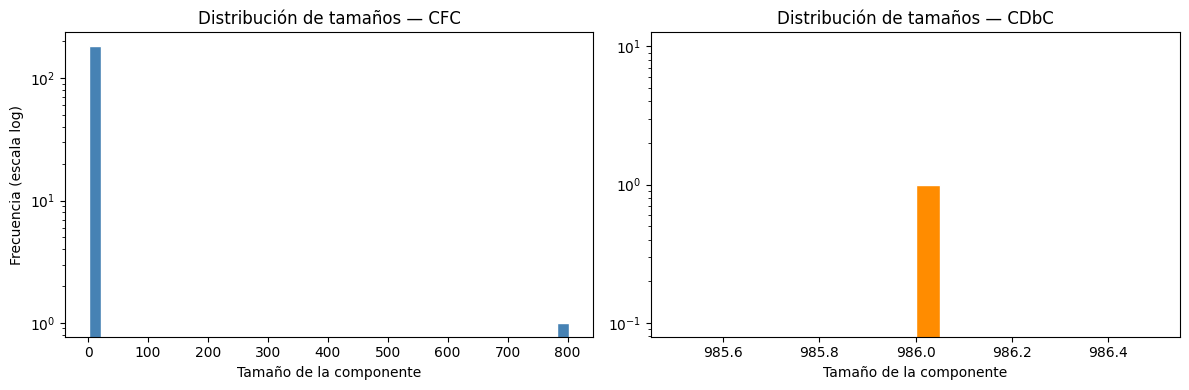


=== Ejemplos de alcanzabilidad (BFS) ===
Nodo    0  (dept  1): alcanza  965 nodos  (97.9 %)
Nodo    1  (dept  1): alcanza    1 nodos  (0.1 %)


In [13]:
# ── Ejecutar algoritmos ────────────────────────────────────────────────────────
import time

t0 = time.time()
cfcs = kosaraju(grafo, grafo_inv, nodos)
t1 = time.time()
wccs = wcc(grafo, grafo_inv, nodos)
t2 = time.time()

cfcs_ord = sorted(cfcs, key=len, reverse=True)
wccs_ord = sorted(wccs, key=len, reverse=True)

print('=== Componentes Fuertemente Conexas (CFC) ===')
print(f'Total de CFCs:         {len(cfcs)}')
print(f'CFC gigante:           {len(cfcs_ord[0])} nodos  ({100*len(cfcs_ord[0])/num_nodos:.1f} %)')
print(f'CFCs de tamaño 1:      {sum(1 for c in cfcs if len(c) == 1)}')
print(f'Tiempo Kosaraju:       {t1-t0:.3f} s')
print()
print('=== Componentes Débilmente Conexas (CDbC) ===')
print(f'Total de CDbCs:        {len(wccs)}')
print(f'CDbC gigante:          {len(wccs_ord[0])} nodos  ({100*len(wccs_ord[0])/num_nodos:.1f} %)')
print(f'Tiempo WCC:            {t2-t1:.3f} s')

# ── Distribución de tamaños ────────────────────────────────────────────────────
tamaños_cfc = [len(c) for c in cfcs]
tamaños_wcc = [len(c) for c in wccs]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(tamaños_cfc, bins=40, color='steelblue', edgecolor='white', log=True)
axes[0].set_title('Distribución de tamaños — CFC')
axes[0].set_xlabel('Tamaño de la componente')
axes[0].set_ylabel('Frecuencia (escala log)')

axes[1].hist(tamaños_wcc, bins=20, color='darkorange', edgecolor='white', log=True)
axes[1].set_title('Distribución de tamaños — CDbC')
axes[1].set_xlabel('Tamaño de la componente')

plt.tight_layout()
plt.show()

# ── Ejemplos de alcanzabilidad (BFS) ──────────────────────────────────────────
nodo_cfc_gigante = next(iter(cfcs_ord[0]))    # nodo dentro de la CFC gigante
nodo_periferico  = next(iter(cfcs_ord[-1]))   # nodo en una CFC de tamaño 1

print('\n=== Ejemplos de alcanzabilidad (BFS) ===')
for origen in [nodo_cfc_gigante, nodo_periferico]:
    alcanzables = bfs_alcanzabilidad(grafo, origen)
    dept = departamento.get(origen, '?')
    print(f'Nodo {origen:>4}  (dept {dept:>2}): '
          f'alcanza {len(alcanzables):>4} nodos  ({100*len(alcanzables)/num_nodos:.1f} %)')

---
# Tarea 4 — Detección de comunidades y comparación con departamentos reales
**Integrante:** Samuel Alejandro Fuentes Sandoval

## 4.1 Descripción del problema

La red registra quién envía correo a quién, mientras que las etiquetas indican el departamento oficial de cada persona. Queremos saber si los patrones de comunicación permiten recuperar esos grupos organizacionales o si, por el contrario, las conversaciones forman comunidades que atraviesan las fronteras entre departamentos. La detección se realiza sin usar las etiquetas; estas se reservan para evaluar el resultado.

La distinción importa: compartir departamento no garantiza comunicarse entre sí, y una persona puede mantener vínculos frecuentes con colegas de otras áreas. Además, el grafo de correo incluye 19 personas etiquetadas que no tienen aristas; se conservan como nodos aislados para que la evaluación cubra a los 1.005 miembros.

## 4.2 Equivalencia matemática

Una comunidad es un subconjunto de vértices de una partición de la red. Se busca una partición con más enlaces internos y menos enlaces entre grupos de los que se esperarían en una red aleatoria con los mismos grados. Para aplicar el algoritmo a la red dirigida, se construye una proyección no dirigida ponderada: cada arco suma una unidad de peso al par de personas, por lo que un vínculo recíproco pesa dos. Los nodos sin aristas permanecen aislados.

La **modularidad** de una partición es:

$$Q = \sum_C \left[\frac{L_C}{m} - \left(\frac{D_C}{2m}\right)^2\right]$$


donde \(m\) es el peso total de las aristas de la proyección, \(L_C\) es el peso de las aristas internas a la comunidad \(C\), y \(D_C\) es la suma de los grados ponderados de sus nodos. Un valor alto indica más cohesión interna que la esperada bajo el modelo nulo de grados. El corte de una comunidad es el peso de las aristas que la conectan con el resto; no se minimiza aisladamente, pues una partición trivial de un solo grupo tendría corte cero.

La **pureza** compara cada comunidad detectada con su departamento mayoritario: suma esos votos mayoritarios y los divide por el número de personas comparables. Va de 0 a 1, pero puede ser alta si se crean muchos grupos pequeños. Por eso también se informa el **índice de Rand ajustado (ARI)**, que compara pares de personas agrupados igual o distinto en ambas particiones y corrige el acuerdo esperado por azar. El ARI vale 1 para particiones idénticas, cerca de 0 para acuerdo aleatorio y puede ser negativo.

## 4.3 Alternativas de solución

| Algoritmo | Descripción | Complejidad aproximada | Observación |
|-----------|-------------|------------------------|-------------|
| Label Propagation | Cada nodo adopta la etiqueta más frecuente entre sus vecinos | O(k · (V + E)) | Muy rápido; puede oscilar o colapsar en una sola comunidad |
| Girvan–Newman | Retira iterativamente aristas con alta intermediación | O(V · E²) | Interpretable, pero costoso para esta red |
| Louvain | Optimiza modularidad mediante movimientos locales y contracción del grafo | Cercana a lineal en la práctica; depende de las iteraciones | Escalable; resultado heurístico y dependiente de la semilla |

Se implementa **Louvain** sin bibliotecas de detección de comunidades. Es apropiado para los 1.005 nodos y permite evaluar la misma función objetivo que reportamos. El código usa movimientos locales, contracción y una semilla fija para que el resultado sea reproducible; el ordenamiento estable de los nodos evita depender del orden interno de los conjuntos de Python.

## 4.4 Implementación

In [14]:
from collections import Counter, defaultdict
import random

def construir_proyeccion_no_dirigida(grafo, nodos):
    """Proyecta los arcos sobre pares no dirigidos, sumando sus pesos."""
    adyacencia = {nodo: {} for nodo in sorted(nodos)}
    for origen in adyacencia:
        for destino in sorted(grafo.get(origen, ())):
            if destino == origen or destino not in adyacencia:
                continue
            adyacencia[origen][destino] = adyacencia[origen].get(destino, 0.0) + 1.0
            adyacencia[destino][origen] = adyacencia[destino].get(origen, 0.0) + 1.0
    return adyacencia


def _optimizar_modularidad_local(adyacencia, generador, max_iter=100):
    """Asigna nodos a comunidades vecinas mientras mejore la modularidad."""
    grados = {nodo: sum(pesos.values()) for nodo, pesos in adyacencia.items()}
    peso_total = sum(grados.values()) / 2
    comunidades = {nodo: nodo for nodo in adyacencia}
    grado_comunidad = grados.copy()
    id_nueva = max(adyacencia, default=0) + 1

    if peso_total == 0:
        return comunidades

    orden_base = sorted(adyacencia)
    for _ in range(max_iter):
        hubo_cambios = False
        orden = orden_base.copy()
        generador.shuffle(orden)

        for nodo in orden:
            comunidad_actual = comunidades[nodo]
            grado = grados[nodo]
            grado_comunidad[comunidad_actual] -= grado

            peso_vecino = defaultdict(float)
            peso_vecino[comunidad_actual] += adyacencia[nodo].get(nodo, 0.0)
            for vecino, peso in adyacencia[nodo].items():
                if vecino != nodo:
                    peso_vecino[comunidades[vecino]] += peso

            candidatos = set(peso_vecino) | {comunidad_actual}
            ganancias = {
                comunidad: peso_vecino.get(comunidad, 0.0)
                - grado * grado_comunidad.get(comunidad, 0.0) / (2 * peso_total)
                for comunidad in candidatos
            }
            mejor_ganancia = max([0.0, *ganancias.values()])
            mejores = [
                comunidad
                for comunidad, ganancia in ganancias.items()
                if abs(ganancia - mejor_ganancia) <= 1e-12
            ]

            if abs(ganancias.get(comunidad_actual, -float("inf")) - mejor_ganancia) <= 1e-12:
                destino = comunidad_actual
            elif mejor_ganancia > 1e-12:
                destino = generador.choice(sorted(mejores))
            else:
                destino = id_nueva
                id_nueva += 1

            if destino != comunidad_actual:
                comunidades[nodo] = destino
                hubo_cambios = True
            grado_comunidad[destino] = grado_comunidad.get(destino, 0.0) + grado

        if not hubo_cambios:
            break

    return comunidades


def _contraer_grafo(adyacencia, comunidades):
    """Contrae cada comunidad a un supernodo y conserva pesos y bucles."""
    grupos = sorted(set(comunidades.values()))
    contraido = {grupo: {} for grupo in grupos}

    for origen in sorted(adyacencia):
        for destino in sorted(adyacencia[origen]):
            peso = adyacencia[origen][destino]
            if origen < destino:
                grupo_origen = comunidades[origen]
                grupo_destino = comunidades[destino]
                if grupo_origen == grupo_destino:
                    contraido[grupo_origen][grupo_origen] = (
                        contraido[grupo_origen].get(grupo_origen, 0.0) + 2 * peso
                    )
                else:
                    contraido[grupo_origen][grupo_destino] = (
                        contraido[grupo_origen].get(grupo_destino, 0.0) + peso
                    )
                    contraido[grupo_destino][grupo_origen] = (
                        contraido[grupo_destino].get(grupo_origen, 0.0) + peso
                    )
            elif origen == destino:
                grupo = comunidades[origen]
                contraido[grupo][grupo] = contraido[grupo].get(grupo, 0.0) + peso

    return contraido


def louvain(grafo, nodos, semilla=112, max_iter=100):
    """Retorna {nodo: comunidad} usando Louvain sobre la proyección ponderada."""
    adyacencia = construir_proyeccion_no_dirigida(grafo, nodos)
    generador = random.Random(semilla)
    miembros = {nodo: {nodo} for nodo in adyacencia}

    while adyacencia:
        comunidades = _optimizar_modularidad_local(
            adyacencia, generador, max_iter=max_iter
        )
        if len(set(comunidades.values())) == len(adyacencia):
            break

        nuevos_miembros = {comunidad: set() for comunidad in set(comunidades.values())}
        for supernodo, comunidad in comunidades.items():
            nuevos_miembros[comunidad].update(miembros[supernodo])
        miembros = nuevos_miembros
        adyacencia = _contraer_grafo(adyacencia, comunidades)

    return {
        nodo: comunidad
        for comunidad, integrantes in miembros.items()
        for nodo in integrantes
    }

In [15]:
def calcular_pureza(comunidades_detectadas, departamento_real):
    """Calcula la pureza sobre los nodos presentes en ambas particiones."""
    nodos_comunes = set(comunidades_detectadas) & set(departamento_real)
    if not nodos_comunes:
        return 0.0

    grupos = defaultdict(Counter)
    for nodo in nodos_comunes:
        grupos[comunidades_detectadas[nodo]][departamento_real[nodo]] += 1
    return sum(max(conteos.values()) for conteos in grupos.values()) / len(nodos_comunes)


def calcular_ari(particion_a, particion_b):
    """Calcula el índice de Rand ajustado a partir de dos particiones."""
    nodos_comunes = set(particion_a) & set(particion_b)
    cantidad = len(nodos_comunes)
    if cantidad < 2:
        return 1.0

    intersecciones = Counter(
        (particion_a[nodo], particion_b[nodo]) for nodo in nodos_comunes
    )
    grupos_a = Counter(particion_a[nodo] for nodo in nodos_comunes)
    grupos_b = Counter(particion_b[nodo] for nodo in nodos_comunes)
    pares_totales = cantidad * (cantidad - 1) / 2
    pares_interseccion = sum(x * (x - 1) / 2 for x in intersecciones.values())
    pares_a = sum(x * (x - 1) / 2 for x in grupos_a.values())
    pares_b = sum(x * (x - 1) / 2 for x in grupos_b.values())
    esperado = pares_a * pares_b / pares_totales
    maximo = (pares_a + pares_b) / 2

    if maximo == esperado:
        return 1.0
    return (pares_interseccion - esperado) / (maximo - esperado)

In [16]:
def calcular_modularidad(grafo, comunidades, nodos=None):
    """Calcula Q en la proyección no dirigida ponderada del grafo."""
    nodos_evaluados = set(comunidades) if nodos is None else set(nodos)
    nodos_evaluados &= set(comunidades)
    adyacencia = construir_proyeccion_no_dirigida(grafo, nodos_evaluados)
    peso_total = sum(sum(pesos.values()) for pesos in adyacencia.values()) / 2
    if peso_total == 0:
        return 0.0

    grado_comunidad = defaultdict(float)
    peso_interno = defaultdict(float)
    for nodo, vecinos in adyacencia.items():
        comunidad = comunidades[nodo]
        grado_comunidad[comunidad] += sum(vecinos.values())
        peso_interno[comunidad] += sum(
            peso
            for vecino, peso in vecinos.items()
            if comunidades.get(vecino) == comunidad
        ) / 2

    return sum(
        peso_interno[comunidad] / peso_total
        - (grado / (2 * peso_total)) ** 2
        for comunidad, grado in grado_comunidad.items()
    )

## 4.5 Resultados y análisis

Con la semilla 112, el algoritmo identifica **37 comunidades** entre los **1.005 nodos** (incluidos los 19 miembros etiquetados sin aristas, que quedan como comunidades singleton). La proyección contiene 16.064 pares no dirigidos distintos y peso total 24.929, pues cada arco dirigido aporta una unidad y los contactos recíprocos aportan dos. Esas comunidades singleton contribuyen a la pureza, por lo que también se informa el ARI.

| Medida | Resultado | Interpretación |
|---|---:|---|
| Modularidad de Louvain | 0,4148 | La partición detectada presenta una estructura interna apreciable |
| Modularidad de los departamentos | 0,2990 | La partición oficial también agrupa enlaces, pero menos que las comunidades detectadas |
| Pureza frente a departamentos | 0,5940 (59,4 %) | En promedio, los grupos tienen una mayoría departamental moderada |
| Índice de Rand ajustado (ARI) | 0,4846 | Coincidencia parcial, superior al azar, pero lejos de una reproducción exacta |

La comunidad más grande reúne **139 personas**; las diez mayores tienen 139, 119, 106, 106, 105, 97, 68, 62, 47 y 31 integrantes. La diferencia entre 37 comunidades detectadas y 42 departamentos, junto con un ARI de 0,4846, muestra que la estructura de comunicación **no reproduce uno a uno** el organigrama: hay agrupaciones que cruzan departamentos y departamentos que se dividen en varios grupos de interacción. La modularidad mayor de Louvain indica que esos grupos describen mejor la cohesión de la red que los departamentos, no que sean una clasificación organizacional “más verdadera”; el resultado depende de la proyección, la heurística y su resolución.

In [17]:
# ── Ejecutar Tarea 4 ─────────────────────────────────────────────────────────
# Incluir también los nodos que tienen etiqueta, pero no aparecen en ninguna arista.
nodos_t4 = set(nodos) | set(departamento)
comunidades_louvain = louvain(grafo, nodos_t4, semilla=112)
com_dist = Counter(comunidades_louvain.values())

pureza_louvain = calcular_pureza(comunidades_louvain, departamento)
ari_louvain = calcular_ari(comunidades_louvain, departamento)
modularidad_louvain = calcular_modularidad(
    grafo, comunidades_louvain, nodos=nodos_t4
)
modularidad_departamentos = calcular_modularidad(
    grafo, departamento, nodos=nodos_t4
)
proyeccion = construir_proyeccion_no_dirigida(grafo, nodos_t4)
pares_no_dirigidos = sum(len(vecinos) for vecinos in proyeccion.values()) // 2
peso_total_proyeccion = sum(
    sum(vecinos.values()) for vecinos in proyeccion.values()
) / 2

print("=== RESULTADOS TAREA 4 — LOUVAIN ===")
print(f"Nodos evaluados:                         {len(nodos_t4)}")
print(f"Pares no dirigidos distintos:            {pares_no_dirigidos}")
print(f"Peso total de la proyección:              {peso_total_proyeccion:.0f}")
print(f"Comunidades detectadas:                   {len(com_dist)}")
print(f"Modularidad de las comunidades:           {modularidad_louvain:.4f}")
print(f"Modularidad de los departamentos:         {modularidad_departamentos:.4f}")
print(f"Pureza frente a departamentos:            {pureza_louvain:.4f}")
print(f"Índice de Rand ajustado (ARI):             {ari_louvain:.4f}")
print("\nTamaño de las 10 comunidades más grandes:")
for posicion, (comunidad, tamano) in enumerate(com_dist.most_common(10), start=1):
    print(f"  Comunidad {posicion:>2} (ID {comunidad}): {tamano:>3} personas")

=== RESULTADOS TAREA 4 — LOUVAIN ===
Nodos evaluados:                         1005
Pares no dirigidos distintos:            16064
Peso total de la proyección:              24929
Comunidades detectadas:                   37
Modularidad de las comunidades:           0.4148
Modularidad de los departamentos:         0.2990
Pureza frente a departamentos:            0.5940
Índice de Rand ajustado (ARI):             0.4846

Tamaño de las 10 comunidades más grandes:
  Comunidad  1 (ID 117): 139 personas
  Comunidad  2 (ID 59): 119 personas
  Comunidad  3 (ID 540): 106 personas
  Comunidad  4 (ID 432): 106 personas
  Comunidad  5 (ID 545): 105 personas
  Comunidad  6 (ID 951):  97 personas
  Comunidad  7 (ID 696):  68 personas
  Comunidad  8 (ID 392):  62 personas
  Comunidad  9 (ID 903):  47 personas
  Comunidad 10 (ID 274):  31 personas


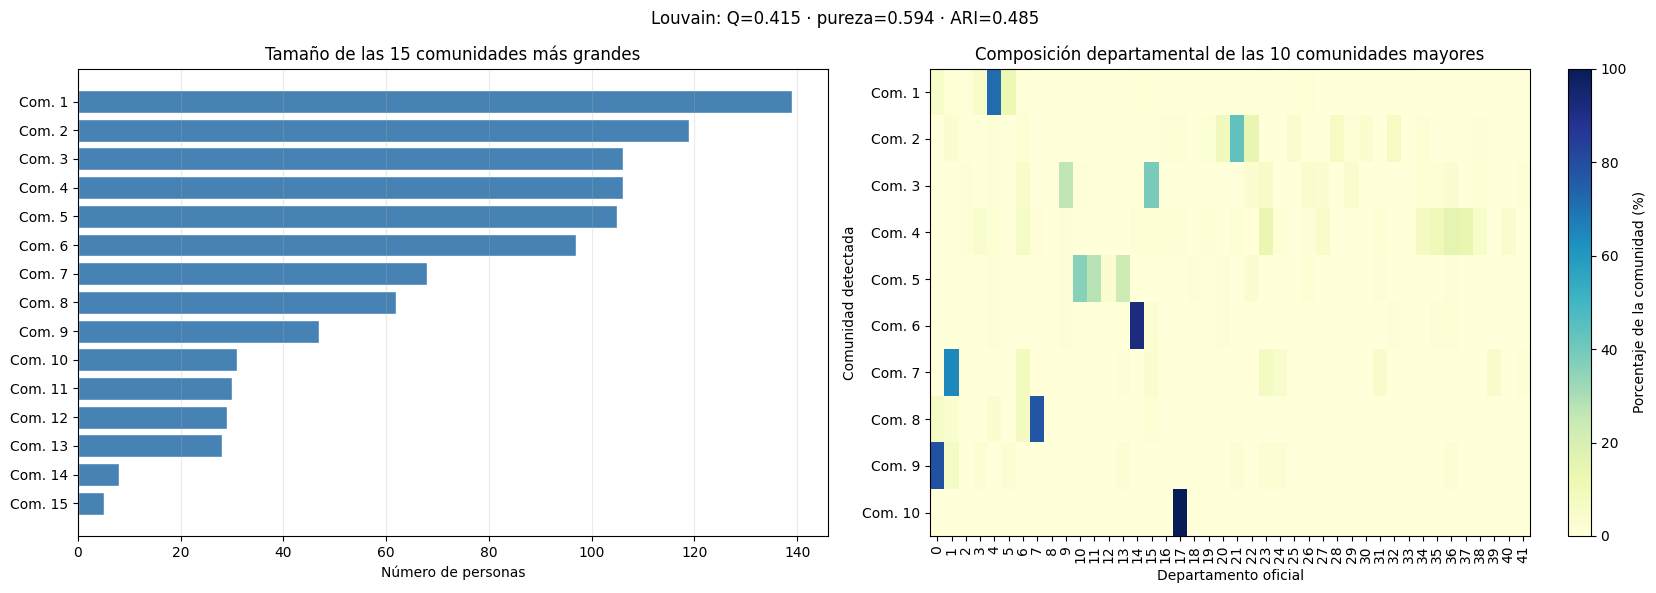

In [18]:
# ── Visualización de resultados — Tarea 4 ────────────────────────────────────
comunidades_ordenadas = com_dist.most_common(15)
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

indices = list(range(len(comunidades_ordenadas)))
axes[0].barh(
    indices,
    [tamano for _, tamano in comunidades_ordenadas],
    color="steelblue",
    edgecolor="white",
)
axes[0].set_yticks(indices)
axes[0].set_yticklabels([f"Com. {i + 1}" for i in indices])
axes[0].invert_yaxis()
axes[0].set_title("Tamaño de las 15 comunidades más grandes")
axes[0].set_xlabel("Número de personas")
axes[0].grid(axis="x", alpha=0.25)

comunidades_grafico = [com for com, _ in com_dist.most_common(10)]
departamentos_grafico = sorted(set(departamento.values()))
composicion = []
for comunidad in comunidades_grafico:
    integrantes = [
        nodo for nodo, com in comunidades_louvain.items() if com == comunidad
    ]
    conteos = Counter(departamento[nodo] for nodo in integrantes if nodo in departamento)
    total = sum(conteos.values())
    composicion.append(
        [100 * conteos[dept] / total if total else 0 for dept in departamentos_grafico]
    )

imagen = axes[1].imshow(composicion, aspect="auto", cmap="YlGnBu", vmin=0, vmax=100)
axes[1].set_yticks(range(len(comunidades_grafico)))
axes[1].set_yticklabels([f"Com. {i + 1}" for i in range(len(comunidades_grafico))])
axes[1].set_xticks(range(len(departamentos_grafico)))
axes[1].set_xticklabels(departamentos_grafico, rotation=90)
axes[1].set_title("Composición departamental de las 10 comunidades mayores")
axes[1].set_xlabel("Departamento oficial")
axes[1].set_ylabel("Comunidad detectada")
fig.colorbar(imagen, ax=axes[1], label="Porcentaje de la comunidad (%)")

fig.suptitle(
    f"Louvain: Q={modularidad_louvain:.3f} · "
    f"pureza={pureza_louvain:.3f} · ARI={ari_louvain:.3f}"
)
plt.tight_layout()
plt.show()

### 🎬 Guion de Exposición: Tarea 4 (Detección de Comunidades)
**Duración estimada:** 1 minuto y 15 segundos a 1 minuto y 25 segundos.
**Tono:** Profesional, dinámico y seguro.

---

#### **[0:00 - 0:15] Introducción y Objetivo**
* **Qué decir:**
En la Tarea 4 nos planteamos una pregunta fundamental: ¿la estructura formal de una organización refleja cómo se comunican realmente sus miembros? Para responderlo, tomamos los 1,005 nodos de la red de correos y aplicamos el algoritmo de Louvain para detectar comunidades reales basadas en el flujo de mensajes, sin usar las etiquetas oficiales de departamentos."
* **Apoyo Visual:** Mostrar el título de la Tarea 4 y mencionar la proyección no dirigida ponderada de la red.

#### **[0:15 - 0:40] Metodología y Algoritmo**
* **Qué decir:** "Implementamos el algoritmo de Louvain desde cero para maximizar la modularidad. Proyectamos las aristas dirigidas en conexiones bidireccionales ponderadas (donde un correo mutuo vale doble) e incluimos a los 19 miembros aislados. Louvain trabaja optimizando localmente y contrayendo la red de forma iterativa para agrupar nodos de manera cohesiva."
* **Apoyo Visual:** Resaltar brevemente la modularidad objetivo ($Q$) en las fórmulas.

#### **[0:40 - 1:10] Resultados Clave y Comparativa**
* **Qué decir:** "¡Los resultados son los siguientes! El algoritmo identificó **37 comunidades**. Al comparar estas comunidades con los 42 departamentos oficiales obtuvimos:
  - Una **Modularidad de Louvain de 0.41**, notablemente superior a la de los departamentos oficiales, que fue de **0.30**. Esto demuestra que la comunicación real es mucho más estrecha internamente que las divisiones del organigrama.
  - Una **pureza del 59%** y un **Índice de Rand Ajustado (ARI) de 0.48**, lo que nos confirma que hay una coincidencia moderada, pero está lejos de ser una copia exacta."
* **Apoyo Visual:** Mostrar el Heatmap de composición departamental y destacar las barras de tamaño de las comunidades.

#### **[1:10 - 1:20] Conclusión**
* **Qué decir:** "En conclusión, el organigrama oficial no limita la colaboración. La red orgánica de comunicación interna de la institución rompe las barreras de los silos departamentales, creando puentes informales de intercambio de información mucho más ricos y complejos. ¡Muchas gracias!"
* **Apoyo Visual:** Hacer zoom o señalar el gráfico de calor donde una comunidad (ej. Comunidad 1 o 10) abarca múltiples departamentos oficiales.

---
# 3. Conclusiones generales

*(Sintetizar los hallazgos más relevantes de las cuatro tareas. Relacionar los resultados entre sí: por ejemplo, ¿coincide el nodo más influyente (Tarea 1) con un nodo que pertenezca a una comunidad grande (Tarea 4)? ¿El departamento más conectado (Tarea 2) es el que tiene más nodos en la SCC principal (Tarea 3)?)*

- La red forma una **única componente débilmente conexa** (986 nodos): ignorando la dirección de los correos, nadie está completamente aislado del resto de la institución.

- Al considerar la dirección, solo el **81.4% de los nodos (803)** pertenecen a la componente fuertemente conexa gigante. *El núcleo donde la información puede circular en cualquier sentido.*

- Los **183 nodos restantes** son completamente periféricos: cada uno forma su propia componente de tamaño 1, es decir, no mantiene comunicación recíproca con nadie.

- Desde un nodo dentro del núcleo activo es posible alcanzar hasta el **97.9% de la red** con un simple BFS; desde un nodo periférico, solo se llega a sí mismo.

- La institución está bien conectada a nivel de infraestructura, pero la **comunicación recíproca está concentrada** en un subconjunto activo de sus miembros.

---
# 4. Referencias

- Yin, H., Benson, A. R., Leskovec, J., y Gleich, D. F. (2017). *Local Higher-order Graph Clustering*. KDD.
- Leskovec, J., Kleinberg, J., y Faloutsos, C. (2007). *Graph Evolution: Densification and Shrinking Diameters*. ACM TKDD, 1(1).
- Cormen, T. H. et al. (2022). *Introduction to Algorithms*, 4th ed. MIT Press. (Capítulos 20–22: grafos, BFS, DFS, SCC.)